# Exercises XP: Guided Student Notebook

This guided notebook follows the **content on the platform**. Some cells are **prefilled** and must be **executed only**. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

**Learning points** appear when a concept is important for intuition or to help you learn new tricks/concepts related to other AI topics.


## Objectives

**What you will learn**  
- The fundamentals of deep learning and neural networks.
- How to build and train simple neural networks using TensorFlow or Keras.
- The concepts of forward and backward propagation.
- How to visualize and interpret model predictions.

**What you will create**  
- A simple perceptron-based decision system.
- A neural network for classifying handwritten digits from the MNIST dataset.
- A forward propagation calculation for predicting house prices.
- A Python implementation of forward and backward propagation.
- Visualizations of predictions made by a neural network on the MNIST dataset.


## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. MNIST is included in Keras, so there is no dataset file to upload. I set random seeds so my results can be repeated.

## 🌟 Exercise 1: Small Quiz

**As stated in the instructions**  
- What is the key difference between traditional machine learning and deep learning?  
- How do artificial neural networks mimic the human brain?  
- Why does deep learning perform better on large datasets compared to traditional machine learning?  
- What are some challenges of deep learning, and how can they be addressed?  
- What is feature engineering, and why is it not needed in deep learning?  
- What role do hidden layers play in a deep learning model?  
- In an artificial neural network, what is the function of an activation function?

**Guidance**  
Answer in full sentences. Use concise definitions first, then add one concrete example for any two questions to demonstrate understanding.

**To-Do:** Write your answers below.


**My answers:**

1. **Traditional ML vs deep learning.** In traditional machine learning I have to do feature engineering: I choose and design the input features myself. Deep learning uses artificial neural networks with many layers that learn the features automatically from raw data (for example, raw pixels of an image).

2. **How ANNs mimic the brain.** The brain has neurons connected by synapses. An ANN has artificial neurons (nodes) connected by weighted links. Each neuron takes inputs, multiplies them by weights, adds a bias, and passes the result through an activation function, a bit like a biological neuron that "fires" or not.

3. **Why DL does better on large datasets.** Traditional ML models plateau when I give them more data. Deep networks have millions of parameters, so more data lets them learn richer patterns, overfit less and generalize better. *Example:* AlphaGo was trained on millions of games to reach superhuman level at Go.

4. **Challenges and how to address them.**
   - *High data requirements* → data augmentation, transfer learning (pre-trained models) or synthetic data.
   - *High computational cost* → GPUs/TPUs or cloud AI services, and smaller models through pruning or quantization.
   - *Lack of interpretability ("black box")* → Explainable AI tools like SHAP and LIME.

5. **Feature engineering.** It is the manual work of selecting and designing input features from the data (for example color histograms or edges for images). Deep learning does not need it because its layers learn the features automatically from raw data. *Example:* a CNN learns edges in its early layers, shapes in the middle layers and full objects (a cat, a car) in the deeper layers.

6. **Role of hidden layers.** Hidden layers are the "thinking" layers between input and output. They transform the data with weights, biases and activation functions and extract patterns. More hidden layers let the network learn more complex, hierarchical features.

7. **Function of an activation function.** It turns the weighted sum of a neuron into its output and decides whether the neuron is "activated". It adds non-linearity: without it the network would just be a linear calculator and could not learn complex patterns.

## 🌟 Exercise 2: Building a Simple Perceptron Decision System

**As stated in the instructions**  
You will create a perceptron-based decision system to decide whether you should go outside based on two inputs:
- Temperature in °F
- Rainy where Yes is 1 and No is 0

Given parameters: Temperature weight 0.6, Rain weight 0.4, Bias 2. Compute the weighted sum
\[ \text{Weighted Sum} = 0.6\cdot \text{Temperature} + 0.4\cdot \text{Rain} + \text{Bias} \]
Apply a step activation:
- If Weighted Sum > 20, output 1
- If Weighted Sum \le 20, output 0

Evaluate:  
Case 1: Temperature 70°F, Rain 0  
Case 2: Temperature 50°F, Rain 1

**Guidance**  
Implement the weighted sum function yourself. Use a reusable step activation. Then compute the two cases and print the decision for each.

**Learning point**  
A perceptron implements a linear decision boundary. The bias shifts the threshold. Use step activation for simple binary rules. Prefer differentiable activations when training with gradient descent.

![image.png](https://github.com/user-attachments/assets/3c4f3261-164d-4039-8e1c-aff2db7162dd)


In [1]:
# PREFILLED: just execute
from typing import Tuple

W_TEMP = 0.6
W_RAIN = 0.4
BIAS   = 2.0

def step_activation(s: float, threshold: float = 20.0) -> int:
    """Return 1 if s > threshold else 0."""
    return 1 if s > threshold else 0


In [2]:
# To-Do: implement weighted_sum then use it to compute the two cases
def weighted_sum(temperature_f: float, rain01: int) -> float:
    """Compute s = 0.6*Temperature + 0.4*Rain + Bias."""
    # To-Do: replace 'pass' with the formula using W_TEMP, W_RAIN, BIAS
    return temperature_f * W_TEMP + rain01 * W_RAIN + BIAS

# To-Do: compute decisions for the two cases and print them
case1 = (70, 0)  # Temperature=70, Rain=0
case2 = (50, 1)  # Temperature=50, Rain=1

s1 = weighted_sum(*case1)
s2 = weighted_sum(*case2)
y1 = step_activation(s1)
y2 = step_activation(s2)

print({"case1": {"sum": round(s1, 2), "decision": y1}, "case2": {"sum": round(s2, 2), "decision": y2}})

{'case1': {'sum': 44.0, 'decision': 1}, 'case2': {'sum': 32.4, 'decision': 1}}


**To-Do:** Interpret your results. Did the perceptron suggest going outside in both cases? Why or why not? Explain using the threshold rule and the effect of bias.


**My answer:**
- **Case 1** (70°F, no rain): weighted sum = 70 × 0.6 + 0 × 0.4 + 2 = **44.0**. 44.0 > 20, so the step function outputs **1 → go outside**.
- **Case 2** (50°F, rain): weighted sum = 50 × 0.6 + 1 × 0.4 + 2 = **32.4**. 32.4 > 20, so the output is also **1 → go outside**.

Yes, the perceptron suggests going outside in both cases, because both sums are above the threshold of 20. The temperature term is so large (42 and 30) that it decides alone. The bias of 2 only shifts the sum up a little, and it makes going outside slightly easier.

I notice that these weights are not very realistic: the rain weight is **positive (+0.4)**, so rain *increases* the sum and pushes towards going outside. To make rain a reason to stay inside, its weight should be negative (and large enough to matter next to the temperature).

## 🌟 Exercise 3: Building a Simple Neural Network with TensorFlow or Keras

**As stated in the instructions**  
Build a classifier for MNIST with:
- One input layer
- One hidden layer with 128 neurons and ReLU activation
- One output layer with 10 neurons and softmax activation

Steps:
1. Import TensorFlow and needed modules from `tensorflow.keras`
2. Load the MNIST dataset
3. Normalize data by dividing by 255.0
4. One-hot encode the labels
5. Build a sequential model with Flatten, Dense(128, ReLU), Dense(10, softmax)
6. Compile with optimizer `adam`, loss `categorical_crossentropy`, metrics `accuracy`
7. Train and evaluate on the test set

**Guidance**  
You will execute prefilled boilerplate for imports and dataset loading. You will complete the one-hot encoding and the model specification, compile, train, and evaluate.

**Learning point**  
Normalization stabilizes optimization. One-hot encoding matches softmax outputs to target vectors. ReLU accelerates training by avoiding saturation, while softmax maps logits to a probability simplex.

![image.png](https://github.com/user-attachments/assets/61737b80-69cb-41a1-aea5-76092cd2a373)


In [3]:
# PREFILLED: just execute
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

print("TensorFlow:", tf.__version__)

# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize to [0,1]
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Flatten will be added in the model; keep images as 28x28 for now
print("Train shape:", x_train.shape, "Test shape:", x_test.shape)


TensorFlow: 2.21.0


Train shape: (60000, 28, 28) Test shape: (10000, 28, 28)


In [4]:
# To-Do: one-hot encode labels y_train and y_test using to_categorical
# Hints: use to_categorical
y_train_oh = to_categorical(y_train, 10)
y_test_oh  = to_categorical(y_test, 10)

print("Labels one-hot:", y_train_oh.shape, y_test_oh.shape)
print("First label:", y_train[0], "->", y_train_oh[0])

Labels one-hot: (60000, 10) (10000, 10)
First label: 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [5]:
# To-Do:  Build a sequential model with Flatten, Dense(128, ReLU), Dense(10, softmax)
tf.keras.utils.set_random_seed(42)  # same starting weights every run

model = models.Sequential([
    layers.Input(shape=(28, 28)),             # input layer: one 28x28 image
    layers.Flatten(),                         # 28x28 -> vector of 784 pixels
    layers.Dense(128, activation='relu'),     # hidden layer
    layers.Dense(10, activation='softmax'),   # output layer: 10 probabilities
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# To-Do: compile the model with adam, categorical_crossentropy, and accuracy
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [7]:
# To-Do: train then evaluate
history = model.fit(x_train, y_train_oh, epochs=5, batch_size=32, validation_split=0.1, verbose=2)
test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
print({"test_loss": round(float(test_loss), 4), "test_acc": round(float(test_acc), 4)})

Epoch 1/5


1688/1688 - 3s - 2ms/step - accuracy: 0.9239 - loss: 0.2672 - val_accuracy: 0.9632 - val_loss: 0.1248


Epoch 2/5


1688/1688 - 2s - 1ms/step - accuracy: 0.9648 - loss: 0.1164 - val_accuracy: 0.9705 - val_loss: 0.0994


Epoch 3/5


1688/1688 - 2s - 1ms/step - accuracy: 0.9764 - loss: 0.0801 - val_accuracy: 0.9705 - val_loss: 0.0950


Epoch 4/5


1688/1688 - 2s - 1ms/step - accuracy: 0.9825 - loss: 0.0604 - val_accuracy: 0.9742 - val_loss: 0.0897


Epoch 5/5


1688/1688 - 2s - 1ms/step - accuracy: 0.9866 - loss: 0.0457 - val_accuracy: 0.9755 - val_loss: 0.0884


{'test_loss': 0.0871, 'test_acc': 0.974}


**My interpretation:** After 5 epochs the training accuracy is 0.9866 and the validation accuracy is 0.9755. On the 10,000 test images the model reaches a **test accuracy of 0.974** (test loss 0.0871), so it recognizes about 97 out of 100 handwritten digits it has never seen. This is a good result for a network with only one hidden layer of 128 neurons. The training accuracy is a little higher than the validation and test accuracy, which is a first small sign of overfitting.

## 🌟 Exercise 4: Forward Propagation Calculation

**As stated in the instructions**  
Predict house prices given:
- Inputs: x₁ = 2000 square feet, x₂ = 3 bedrooms
- Weights: w₁ = 0.5, w₂ = 0.7
- Bias: b = 50,000
- Activation: ReLU

Compute z before activation, apply ReLU, and interpret the prediction.

**Guidance**  
Write scalar computations. Then reason about the role of the bias and ReLU on the output scale.

**Learning point**  
ReLU passes positive linear combinations unchanged and zeros out negatives. Bias sets the baseline prediction independent of inputs.
![](./figs/1.gif)

In [8]:
# To-Do: compute forward propagation for the given numbers
x1, x2 = 2000.0, 3.0
w1, w2 = 0.5, 0.7
b = 50000.0

# To-Do: compute z = x1*w1 + x2*w2 + b
z = x1*w1 + x2*w2 + b

# To-Do: apply ReLU
y = max(0.0, z) #Hint: ReLU acts like max functions and leaves only positive outputs

print({"z": round(z, 2), "prediction": round(y, 2)})

{'z': 51002.1, 'prediction': 51002.1}


**To-Do:** Interpret the result as a house price. Explain the influence of input scaling and bias in full sentences.


**My answer:** z = 2000 × 0.5 + 3 × 0.7 + 50,000 = 1,000 + 2.1 + 50,000 = **51,002.1**. Because z is positive, ReLU keeps it unchanged, so the predicted house price is **$51,002.10**.

Most of this price comes from the bias (50,000), which is the baseline price before looking at the house. Square footage adds 1,000, and the 3 bedrooms add only 2.1, because the bedroom number is small (3) compared with the square footage (2000). The inputs are on very different scales, so the bigger input dominates. This is why we normally scale the inputs before training. These weights are not trained, so the price itself is just the result of the given numbers, not a realistic estimate.

## 🌟 Exercise 5 (optional): Implementing Forward and Backward Propagation in Python

**As stated in the enoncé**  
You will code a simple neural network that performs forward propagation and backpropagation for a regression problem predicting exam scores from study hours.

**Guidance**  
Run the prefilled code. Then modify the learning rate or initial weights and observe changes in the loss and updates.
Provide a short written explanation.

**Learning point**  
Gradient descent updates parameters in the direction of steepest loss reduction.
The learning rate controls step size. Too small slows learning. Too large risks divergence.


In [9]:
# PREFILLED: just execute
import numpy as np

# Initialize input data (features)
x = np.array([4, 80])  # 4 hours studied, previous test score: 80

# Initialize weights and bias
w = np.array([0.6, 0.3])  # Initial weights
b = 10  # Initial bias

# Forward Propagation
def forward_propagation(x, w, b):
    z = np.dot(x, w) + b  # Weighted sum
    return z  # Linear activation (No ReLU here, it's a regression task)

# Compute prediction
y_pred = forward_propagation(x, w, b)
y_true = 85  # Actual exam score

# Compute Loss (Mean Squared Error)
loss = 0.5 * (y_true - y_pred) ** 2

# Compute Gradients
grad_w = -(y_true - y_pred) * x  # Partial derivatives with respect to weights
grad_b = -(y_true - y_pred)  # Partial derivative with respect to bias

# Update Weights and Bias
learning_rate = 0.01
w_new = w - learning_rate * grad_w
b_new = b - learning_rate * grad_b

# Print Results
print("Initial Prediction:", y_pred)
print("Loss:", loss)
print("Updated Weights:", w_new)
print("Updated Bias:", b_new)


Initial Prediction: 36.4
Loss: 1180.98
Updated Weights: [ 2.544 39.18 ]
Updated Bias: 10.486


I see that one update with learning rate 0.01 changes the weights a lot: w₂ jumps from 0.3 to 39.18. Below I check what happens to the prediction if I keep updating, and I try other learning rates and initial weights.

In [10]:
# My experiment: repeat the same update several times and watch the loss
def train_steps(x, w, b, y_true, learning_rate, steps=5):
    w = w.astype(float).copy()
    losses = []
    for step in range(steps):
        y_pred = forward_propagation(x, w, b)
        losses.append(0.5 * (y_true - y_pred) ** 2)
        grad_w = -(y_true - y_pred) * x
        grad_b = -(y_true - y_pred)
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b
    return w, b, forward_propagation(x, w, b), losses

for lr_try, w_start in [(0.01, [0.6, 0.3]), (0.001, [0.6, 0.3]), (0.0001, [0.6, 0.3]), (0.0001, [1.0, 0.8])]:
    w_end, b_end, pred_end, losses = train_steps(x, np.array(w_start), 10, y_true, lr_try)
    print(f"lr={lr_try:<7} start w={w_start}  losses per step: {[f'{l:.4g}' for l in losses]}  prediction after 5 steps: {pred_end:.4g}")

lr=0.01    start w=[0.6, 0.3]  losses per step: ['1181', '4.713e+06', '1.881e+10', '7.504e+13', '2.995e+17']  prediction after 5 steps: 4.889e+10
lr=0.001   start w=[0.6, 0.3]  losses per step: ['1181', '3.465e+04', '1.017e+06', '2.984e+07', '8.756e+08']  prediction after 5 steps: 2.268e+05
lr=0.0001  start w=[0.6, 0.3]  losses per step: ['1181', '151.6', '19.46', '2.499', '0.3208']  prediction after 5 steps: 84.71
lr=0.0001  start w=[1.0, 0.8]  losses per step: ['24.5', '3.145', '0.4038', '0.05184', '0.006655']  prediction after 5 steps: 84.96


**To-Do:** Explain in full sentences why updating weights using gradient descent reduces the error. Then modify the learning rate or initial weights and describe how this affects learning.


**My answer:** With the given code, the first prediction is 36.4 while the real score is 85, so the loss is 1180.98. Both gradients are negative (the prediction is too low), so subtracting them *increases* the weights to [2.544, 39.18] and the bias to 10.486.

**Why gradient descent reduces the error:** the gradient tells me in which direction the loss grows and how strongly each weight affects it. When I move each weight a small step in the *opposite* direction of its gradient, the loss goes down. Repeating this many times brings the prediction closer to the true value.

**What I see when I change the settings (my experiment above):**
- With **learning rate 0.01** the step is far too big for this data. The second input (80) is large, so w₂ jumps from 0.3 to 39.18 and the loss goes from 1181 to 4.713e+06 after one step and keeps exploding: training *diverges*. Learning rate 0.001 still diverges (loss 3.465e+04 after one step).
- With **learning rate 0.0001** the loss goes down at every step (1181 → 151.6 → 19.46 → 2.499 → 0.3208) and the prediction reaches 84.71, very close to 85.
- With **better initial weights [1.0, 0.8]** and learning rate 0.0001, the loss starts much lower (24.5) and after 5 steps the prediction is 84.96.

So the learning rate must fit the size of the inputs: too large overshoots, a smaller one learns step by step. This is also why we usually scale the inputs before training.

## 🌟 Exercise 6 (optional): Visualizing Predictions on MNIST

**As stated in the enoncé**  
Train a simple model on MNIST, then visualize predictions for some test images with predicted labels.

**Guidance**  
Reuse the model from Exercise 3 if still in memory. Otherwise re-run Exercise 3. Plot a grid of test images with predicted labels and optionally true labels.

**Learning point**  
Softmax outputs are probabilities over classes. Inspect the confidence values. Visual errors often indicate confusions between similar digits.

![image.png](https://github.com/user-attachments/assets/e00d3913-55d4-4b62-8f70-1216bcc2e4e4)


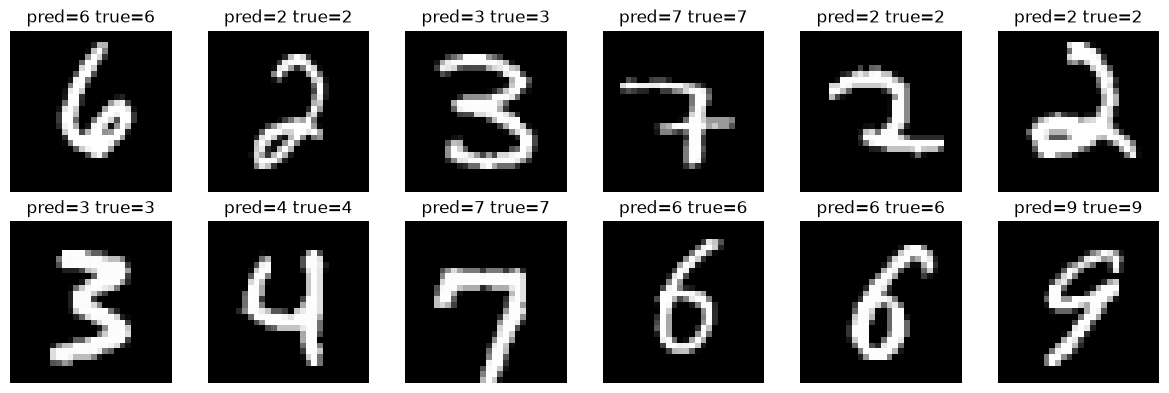

Correct: 12 of 12
Confidence of each prediction: [1.    0.999 1.    0.999 0.857 1.    1.    1.    1.    0.999 1.    0.841]


In [11]:
# To-Do: visualize a few predictions with matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Ensure we have the model and x_test, y_test from Exercise 3
# To-Do: select N samples from x_test by using np.random.choice
np.random.seed(42)
idx = np.random.choice(len(x_test), size=12, replace=False)
x_vis = x_test[idx]
y_true = y_test[idx]

# To-Do: get predictions
y_prob = model.predict(x_vis, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

#plotting
cols = 6
rows = int(np.ceil(len(idx)/cols))
plt.figure(figsize=(12, 2*rows))
for i, k in enumerate(idx, 1):
    plt.subplot(rows, cols, i)
    plt.imshow(x_test[k], cmap="gray")
    plt.title(f"pred={y_pred[i-1]} true={y_true[i-1]}" )
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Correct:", int((y_pred == y_true).sum()), "of", len(idx))
print("Confidence of each prediction:", np.round(y_prob.max(axis=1), 3))

**My interpretation:** I picked 12 random test images and the model from Exercise 3 predicted **all 12 correctly**. Most predictions have a confidence of 0.999 or 1.0. Two images got a lower confidence (0.857 and 0.841): even when the answer is right, the model is less sure on digits that are written in an unusual way. The softmax output gives me these probabilities, so I can see not only the predicted digit but also how confident the network is.